# Фаза по траектории Надарая—Ватсона

## Импорты и параметры

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy import stats
from statsmodels.tsa.stattools import kpss
from sklearn.decomposition import PCA
from my_lib import HankelMatrix, prepare_time_series, NWregression

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

START = 7174
T = 462
N_STEPS = 20
WINDOW = 500
N_COMPONENTS = 4
M = 900
N_PREDICT = 4000
OUTPUT = Path('output')
OUTPUT.mkdir(exist_ok=True)

## Запись ходьбы

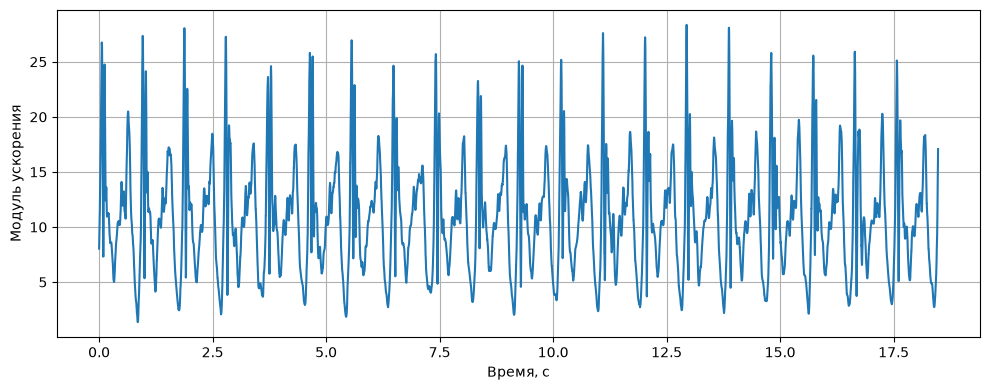

In [2]:
signal, time = prepare_time_series('data/long_walk_100_acc.csv', centred=False)
x_acc = signal[START:START + T * N_STEPS]
t = np.arange(len(x_acc)) / 500

plt.plot(t, x_acc)
plt.xlabel('Время, с')
plt.ylabel('Модуль ускорения')
plt.tight_layout()
plt.show()

## Окна и PCA

Окно из 500 отсчётов заменяем четырьмя координатами.

In [3]:
X_h = HankelMatrix(x_acc, WINDOW)
pca = PCA(n_components=N_COMPONENTS, svd_solver='full')
X_PCA = pca.fit_transform(X_h)
print(f'Окна: {X_h.shape}; PCA: {X_PCA.shape}')

Окна: (8741, 500); PCA: (8741, 4)


## Начальные фазы

Фазы заданы равномерно на всём отрезке. Период разметки — 460 отсчётов; `T=462` используется для выбора длины записи.

In [4]:
phis = np.linspace(0, 2 * np.pi * (N_STEPS - 1), len(X_PCA)) % (2 * np.pi)
phis = phis.reshape(-1, 1)
phi_mean = (2 * np.pi * np.arange(M) / M).reshape(-1, 1)
print(f'Пары обучения: {phis.shape} → {X_PCA.shape}')

Пары обучения: (8741, 1) → (8741, 4)


## Средняя траектория

Регрессия получает фазу и усредняет PCA-точки с близкими фазами. Используются круговая мера близости и прямоугольное ядро.

In [5]:
def phase_distance(x, y):
    return (1 - np.cos(x - y)) / 2


model = NWregression(h=2.1 * np.pi / M, kernel='rectangular', metric=phase_distance)
model.fit(phis, X_PCA)
regression = model.predict(phi_mean)

## Радиус поиска

`D` — максимальное расстояние от обучающей точки до ближайшей точки средней кривой. Радиус общий для всех фаз.

In [6]:
distances = cdist(X_PCA, regression)
nearest_distances = distances.min(axis=1)
D = nearest_distances.max()
assert np.all(nearest_distances <= D)
print(f'D = {D:.3f}; покрытие: {len(nearest_distances)} из {len(X_PCA)} окон')

D = 23.453; покрытие: 8741 из 8741 окон


## Выбор фазы

Среди кандидатов в радиусе `D` минимизируем `L1 + L2`. Средняя кривая фиксирована; `L3` не используется.

In [7]:
phase_history = []
x_phase_history = {}

for i, point in enumerate(X_PCA[:N_PREDICT]):
    candidates = np.flatnonzero(distances[i] <= D)
    candidate_phases = phi_mean[candidates, 0]

    if i == 0:
        best_index = int(np.argmin(distances[i]))
    else:
        delta = phase_history[-1] - candidate_phases
        loss1 = np.where((delta > 0) & (delta < np.pi / 2), delta, 0)
        neighbour_phases = np.array([
            phase for phase, previous_point in x_phase_history.items()
            if np.linalg.norm(point - previous_point) <= D / 3
        ])
        loss2 = phase_distance(neighbour_phases[:, None], candidate_phases[None, :]).sum(axis=0)
        best_index = int(candidates[np.argmin(loss1 + loss2)])

    phase = float(phi_mean[best_index, 0])
    phase_history.append(phase)
    x_phase_history[phase] = point.copy()

phase_history = np.asarray(phase_history)
assert len(phase_history) == min(N_PREDICT, len(X_PCA))
assert np.isfinite(phase_history).all()

## Оценённая фаза

Первые 4000 окон той же выборки, по которой построена средняя кривая.

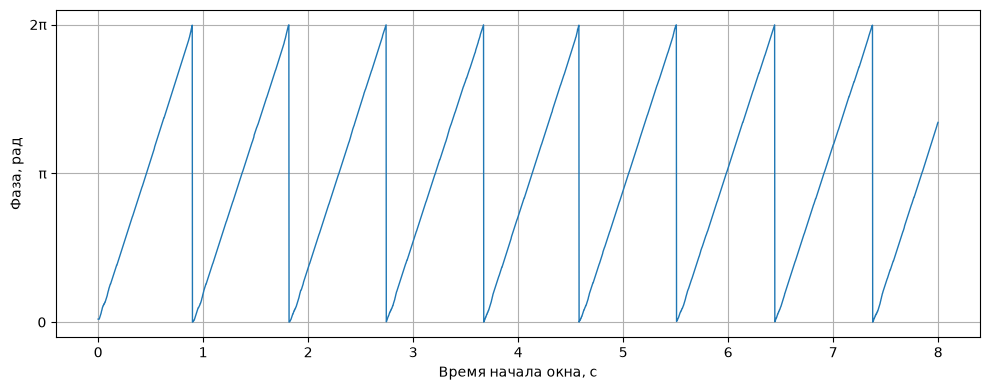

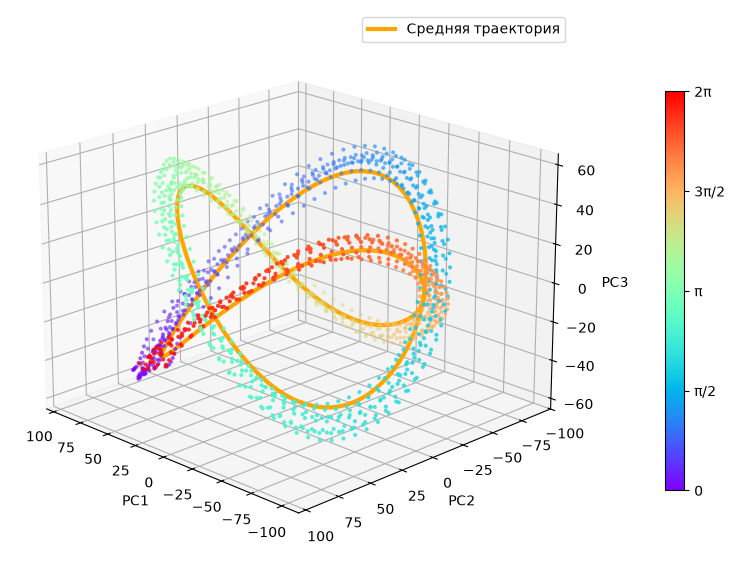

In [8]:
plt.plot(np.arange(len(phase_history)) / 500, phase_history, linewidth=1)
plt.xlabel('Время начала окна, с')
plt.ylabel('Фаза, рад')
plt.yticks([0, np.pi, 2 * np.pi], ['0', 'π', '2π'])
plt.tight_layout()
plt.show()

points = X_PCA[:len(phase_history):3]
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(points[:, 0], points[:, 1], points[:, 2],
                     c=phase_history[::3], cmap='rainbow', vmin=0, vmax=2 * np.pi, s=4)
ax.plot(regression[:, 0], regression[:, 1], regression[:, 2],
        color='orange', linewidth=3, label='Средняя траектория')
ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3')
ax.view_init(elev=20, azim=135)
ax.legend()
colorbar = fig.colorbar(scatter, ax=ax, shrink=0.7, pad=0.12)
colorbar.set_ticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
                   labels=['0', 'π/2', 'π', '3π/2', '2π'])
fig.tight_layout()
fig.savefig(OUTPUT / 'phas_final.png', dpi=200)
plt.show()

## Остатки средней траектории

Проверяем остатки первой PCA-координаты. Эти тесты не измеряют ошибку фазы.

In [9]:
residuals = (X_PCA - model.predict(phis))[:, 0]
checks = [
    ('Нормальность', 'Шапиро—Уилка', min(5000, len(residuals)),
     stats.shapiro(residuals[:5000]).pvalue),
    ('Нулевой сдвиг', 'Уилкоксона', len(residuals), stats.wilcoxon(residuals).pvalue),
    ('Стационарность', 'KPSS', len(residuals), kpss(residuals, regression='c', nlags='auto')[1]),
]
table = pd.DataFrame(checks, columns=['Гипотеза', 'Критерий', 'Число точек', 'p-value'])
table['Результат при α=0.05'] = np.where(table['p-value'] < 0.05, 'отвергается', 'не отвергается')
table

/var/folders/g6/5fnjg_911ds0hsfgqdjm4__h0000gn/T/ipykernel_47254/3977888590.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  ('Стационарность', 'KPSS', len(residuals), kpss(residuals, regression='c', nlags='auto')[1]),
/var/folders/g6/5fnjg_911ds0hsfgqdjm4__h0000gn/T/ipykernel_47254/3977888590.py:6: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  ('Стационарность', 'KPSS', len(residuals), kpss(residuals, regression='c', nlags='auto')[1]),


,Гипотеза,Критерий,Число точек,p-value,Результат при α=0.05
0,Нормальность,Шапиро—Уилка,5000,2.205690e-19,отвергается
1,Нулевой сдвиг,Уилкоксона,8741,7.532197e-01,не отвергается
2,Стационарность,KPSS,8741,1.000000e-01,не отвергается
